# Phase 2c -- Side analyses of the pair test

These analyses re-use the Phase 2 test but are **not** part of its main line (notebook 02). They
describe other patient groups or check specific concerns, and none changes the 1,609 interaction
candidates. Validation of the main result is in notebook 02b.

| Section | Question |
|---|---|
| A | What do hypermutated tumours show on their own? |
| B | What if only mutations count (every patient with mutation data)? |
| C | Copy-number burden: do co-occurrences survive grouping patients by genome instability? |
| D | Fusion screen: what goes with ALK, ROS1, RET, ERG ...? |
| E | Is the result driven by mutation load? (van de Haar 2019 diagnostic) |
| F | Method comparison on real data: significant lists in TCGA, and ranking by effect size |

Run after notebook 02. Section C adds the `burden_*` columns to `comutation_pairs.parquet`; Sections E-F read the outputs of `scripts/analyses/15` and `21`.

## Setup: the Phase 2 settings, data and test (from notebook 02)

In [1]:
import json
from contextlib import contextmanager

# Run notebook 02's settings, data-loading and test cells, so this notebook uses exactly the same
# patients, filters and test (cells are looked up by id, which does not change when text is edited).
_nb02 = {c.get("id"): "".join(c["source"]) for c in json.load(open("02_phase2_comutation_matrix.ipynb"))["cells"]}
for _cid in ["8455b24e", "57159198", "332f818c", "e3d5f851", "disc0v3rcd", "17d9c817", "056ff63e"]:
    exec(_nb02[_cid], globals())
main_cancer_types = qualifying_cancer_types   # as in notebook 02, Step 3


@contextmanager
def analysing(**overrides):
    """Temporarily swap notebook-level settings/data (e.g. which patients), then restore."""
    saved = {k: globals()[k] for k in overrides}
    globals().update(overrides)
    try:
        yield
    finally:
        globals().update(saved)


comutation_pairs = pd.read_parquet(PROCESSED_DIR / "comutation_pairs.parquet")
mechanism_pairs = pd.read_parquet(PROCESSED_DIR / "mechanism_pairs.parquet")
print(f"Phase 2 table: {len(comutation_pairs):,} pairs, {comutation_pairs['interaction_candidate'].sum():,} candidates")
P = str(PROCESSED_DIR) + "/"   # saved outputs of scripts/analyses (Sections E-F)

from Phase 1: 227,696 patients (one sample each), 1,723,487 driver events
TMB_GROUP
non_hypermutated    159390
unknown              43196
hypermutated         24452
ultramutated           658


main analysis group (not_hypermutated): 159,390 of 227,696 patients
(845494, 18) (58876, 2) (17994, 2) (159390, 28)
CNV_Driver_Status
Driver_Consistent    170990
Unannotated           42478
56 of 109 cancer types have >= 100 copy-number-tested patients
Phase 2 table: 6,871 pairs, 1,609 candidates


## A. Hypermutated tumours on their own

TMB 10-100 only: ultramutated tumours (TMB >= 100, mostly POLE) are a different mutational process --
pooled with the rest they made 21.6% of endometrial pairs "significant" (0.3% and 0% when separated).
Result: a description of mostly subtype structure (MSI vs MSS), not new interactions (notebook 04, Section 5).

In [2]:
# --- (2) Hypermutated patients on their own ---------------------------------
# TMB 10-100 only: ultramutated tumours (TMB >= 100, mostly POLE) are a different
# mutational process -- pooled with the rest they made 21.6% of endometrial pairs
# "significant" (0.3% and 0% when separated) -- and too few per cancer type to test.
status_summary = []
for ct in qualifying_cancer_types:
    ct_all = clinical_all[(clinical_all["CANCER_TYPE"] == ct) & clinical_all["CNA_TESTED"]]
    counts = ct_all["HYPERMUTATION_STATUS"].value_counts()
    status_summary.append({"Cancer_Type": ct, "n_total": int(len(ct_all)),
                           **{f"n_{k}": int(counts.get(k, 0)) for k in ("hypermutated", "not_hypermutated", "unknown")},
                           "n_ultramutated": int((ct_all["TMB_MUT_PER_MB"] >= ULTRAMUTATED_TMB).sum())})
pd.DataFrame(status_summary).to_parquet(PROCESSED_DIR / "hypermutation_status_by_cancer_type.parquet", index=False)

hyper_patients = clinical_all[(clinical_all["HYPERMUTATION_STATUS"] == "hypermutated")
                              & (clinical_all["TMB_MUT_PER_MB"] < ULTRAMUTATED_TMB)]
hyper_frames = []
with analysing(clinical=hyper_patients,
               alterations=alterations_all[alterations_all["Sample_ID"].isin(hyper_patients["SAMPLE_ID"])]):
    for ct in tqdm(qualifying_cancer_types, desc="hypermutated group"):
        res = test_cancer_type(ct, require_cna_tested=True)
        if not res.empty:
            res["q_value"] = bh_fdr(res["p_value"].to_numpy())
            hyper_frames.append(res)
comutation_pairs_hyper = pd.concat(hyper_frames, ignore_index=True)
comutation_pairs_hyper.to_parquet(PROCESSED_DIR / "comutation_pairs_hypermutated.parquet", index=False)
print(f"hypermutated group (TMB 10-{ULTRAMUTATED_TMB}): {len(comutation_pairs_hyper):,} pairs in "
      f"{comutation_pairs_hyper['Cancer_Type'].nunique()} cancer types, "
      f"{(comutation_pairs_hyper['q_value'] < 0.05).sum():,} significant")


hypermutated group:   0%|          | 0/56 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:267: RuntimeWarning: overflow encountered in multiply
<string>:274: RuntimeWarning: overflow encountered in multiply


hypermutated group (TMB 10-100): 99,429 pairs in 18 cancer types, 881 significant


## B. Mutations only

"Altered" = protein-changing mutation only, so copy-number data are not needed and every patient with
mutation data counts. Mutation calls are the most consistent between centres (replication 84%), and the
directions agree with the main analysis in 98.9% of pairs significant in both (notebook 04, Step 4).

In [3]:
# --- (3) Mutation-only analysis ---------------------------------------------
# "Altered" = protein-changing mutation only, so copy-number data is not needed and
# every patient with mutation data counts (not just the copy-number-tested ones).
mut_alterations = alterations[alterations["Alteration_Type"] == "MUT"]
mut_counts = clinical.loc[clinical["MUT_TESTED"], "CANCER_TYPE"].value_counts()
mut_cancer_types = [ct for ct in mut_counts[mut_counts >= MIN_SAMPLES_PER_CANCER_TYPE].index
                    if ct not in EXCLUDED_CANCER_TYPES]
mut_frames = []
for ct in tqdm(mut_cancer_types, desc="mutation-only"):
    res = test_cancer_type(ct, alt_source=mut_alterations, mutation_only=True)
    if not res.empty:
        res["q_value"] = bh_fdr(res["p_value"].to_numpy())
        mut_frames.append(res)
comutation_pairs_mut = pd.concat(mut_frames, ignore_index=True)
comutation_pairs_mut.to_parquet(PROCESSED_DIR / "comutation_pairs_mutation_only.parquet", index=False)
print(f"mutation-only: {len(comutation_pairs_mut):,} pairs in {len(mut_frames)} cancer types "
      f"({mut_counts[mut_cancer_types].sum():,} patients), "
      f"{(comutation_pairs_mut['q_value'] < 0.05).sum():,} significant")


mutation-only:   0%|          | 0/61 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

mutation-only: 2,554 pairs in 57 cancer types (155,020 patients), 615 significant


## C. Copy-number burden (sensitivity flag)

The conditional test conditions on each patient's *total* number of alterations, but a gene that
sits on an unmeasured amplicon can still act as a marker of a generally unstable, "amplifier"
tumour and pair with other amplified genes for that reason alone. This concern has published
precedent: CDCOCA (Kumar et al. 2011) and Zack et al. 2013 both found that copy-number
co-occurrence must be judged against each tumour's overall copy-number complexity.

Building burden into the main test was tried (`scripts/analyses/13_burden_strata.py`):
counting burden from all genes over-adjusts -- a pair amplified together raises its own
patient's burden, so the famous breast *CCND1*/*FGFR1* co-amplification disappeared; counting
only genes *outside* the analysis avoids that but did not improve out-of-centre replication
(64% vs 66%). So burden is used as a **sensitivity check** rather than the default: every pair
is re-tested with gene rates fitted within subtype x burden groups (0 / 1-3 / >= 4 deep
copy-number calls in genes outside the analysis), and `burden_robust` records whether a
significant pair survives.

In [4]:
cnv_rows = alterations[alterations["Alteration_Type"] == "CNV"]
sens_frames = []
for ct, ct_pairs in tqdm(comutation_pairs.groupby("Cancer_Type"), desc="burden sensitivity"):
    genes = set(ct_pairs["Gene_A"]) | set(ct_pairs["Gene_B"])
    outside = cnv_rows[(cnv_rows["CANCER_TYPE"] == ct) & ~cnv_rows["Hugo_Symbol"].isin(genes)]
    n_cnv = clinical["SAMPLE_ID"].map(outside.groupby("Sample_ID").size()).fillna(0)
    group = np.select([n_cnv == 0, n_cnv <= 3], ["cnv0", "cnv1-3"], "cnv4+")
    with analysing(clinical=clinical.assign(BURDEN_STRATUM=clinical["SUBTYPE_STRATUM"] + "|" + group),
                   STRATUM_COLUMN="BURDEN_STRATUM"):
        res = test_cancer_type(ct, allowed_genes=genes, require_cna_tested=True)
    if not res.empty:
        res["burden_q_value"] = bh_fdr(res["p_value"].to_numpy())
        sens_frames.append(res.rename(columns={"direction": "burden_direction"})[
            ["Cancer_Type", "Gene_A", "Gene_B", "burden_q_value", "burden_direction"]])
# drop any burden columns from an earlier run, so re-running this section gives the same table
comutation_pairs = comutation_pairs.drop(columns=["burden_q_value", "burden_direction", "burden_robust"], errors="ignore")
comutation_pairs = comutation_pairs.merge(pd.concat(sens_frames, ignore_index=True),
                                          on=["Cancer_Type", "Gene_A", "Gene_B"], how="left")
comutation_pairs["burden_robust"] = ((comutation_pairs["burden_q_value"] < 0.05)
                                     & (comutation_pairs["burden_direction"] == comutation_pairs["direction"]))
_sig = comutation_pairs["q_value"] < 0.05
print(f"significant pairs that survive the burden sensitivity check: "
      f"{(_sig & comutation_pairs['burden_robust']).sum():,} of {_sig.sum():,}")

burden sensitivity:   0%|          | 0/52 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


significant pairs that survive the burden sensitivity check: 1,532 of 1,851


In [5]:
comutation_pairs.to_parquet(PROCESSED_DIR / "comutation_pairs.parquet", index=False)
print("comutation_pairs.parquet updated with the burden_* columns")

comutation_pairs.parquet updated with the burden_* columns


## D. Fusion screen: what goes with ALK, ROS1, RET, ERG ...?

Gene fusions (Phase 1 Section 4c) are a third kind of alteration. Most are too rare to pass the
3% gene filter, yet they are exactly what clinicians ask about ("an ALK-fusion lung cancer --
what else should I expect?"). Each fusion with >= `MIN_FUSION_CARRIERS` carriers in a cancer
type is tested with the same conditional test against that cancer type's analysis genes and
against the other fusions, using only patients whose panel can detect it (filters 3 and 4
apply as usual; BH-FDR within each cancer type, across the fusion pairs).

In [6]:
fusion_rows = alterations[alterations["Alteration_Type"] == "SV"]
fus_frames = []
for ct in tqdm(qualifying_cancer_types, desc="fusion screen"):
    carriers = fusion_rows[fusion_rows["CANCER_TYPE"] == ct].groupby("Hugo_Symbol")["Sample_ID"].nunique()
    fusions_here = set(carriers[carriers >= MIN_FUSION_CARRIERS].index)
    if not fusions_here:
        continue
    ct_pairs = comutation_pairs[comutation_pairs["Cancer_Type"] == ct]
    genes = (set(ct_pairs["Gene_A"]) | set(ct_pairs["Gene_B"])) - set(fusion_rows["Hugo_Symbol"])
    with analysing(MIN_GENE_ALT_FRACTION=0.0, MIN_GENE_ALT_ABS=1):
        res = test_cancer_type(ct, allowed_genes=genes | fusions_here, require_cna_tested=True)
    if res.empty:
        continue
    res = res[res["Gene_A"].isin(fusions_here) | res["Gene_B"].isin(fusions_here)].copy()
    if res.empty:
        continue
    res["q_value"] = bh_fdr(res["p_value"].to_numpy())
    fus_frames.append(res)
comutation_pairs_fusions = pd.concat(fus_frames, ignore_index=True)
comutation_pairs_fusions.to_parquet(PROCESSED_DIR / "comutation_pairs_fusions.parquet", index=False)
_s = comutation_pairs_fusions[comutation_pairs_fusions["q_value"] < 0.05]
print(f"fusion screen: {len(comutation_pairs_fusions):,} pairs in {comutation_pairs_fusions['Cancer_Type'].nunique()} "
      f"cancer types, {len(_s):,} significant ({(_s['direction'] == 'exclusive').sum():,} exclusive)")
_s.sort_values("q_value")[["Cancer_Type", "Gene_A", "Gene_B", "n_both_altered", "expected_both",
                           "fold_enrichment", "direction", "q_value"]].head(20)

fusion screen:   0%|          | 0/56 [00:00<?, ?it/s]

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


...

<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=

fusion screen: 375 pairs in 18 cancer types, 132 significant (107 exclusive)


<string>:69: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
<string>:20: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


,Cancer_Type,Gene_A,Gene_B,n_both_altered,expected_both,fold_enrichment,direction,q_value
58,Non-Small Cell Lung Cancer,ALK_fusion,EGFR,4,140.185594,0.031986,exclusive,4.037336e-53
299,Prostate Cancer,ERG_fusion,SPOP,11,149.720484,0.076554,exclusive,4.072399e-51
64,Non-Small Cell Lung Cancer,ALK_fusion,KRAS,5,131.828884,0.041563,exclusive,2.398417e-48
79,Non-Small Cell Lung Cancer,ALK_fusion,STK11,0,59.053834,0.008396,exclusive,9.576972e-25
132,Non-Small Cell Lung Cancer,KRAS,RET_fusion,2,61.373852,0.040405,exclusive,1.511797e-22
133,Non-Small Cell Lung Cancer,KRAS,ROS1_fusion,0,48.925642,0.010116,exclusive,1.856199e-20
108,Non-Small Cell Lung Cancer,EGFR,ROS1_fusion,2,52.572330,0.047106,exclusive,5.693111e-19
290,Prostate Cancer,ERG_fusion,FOXA1,77,179.191720,0.431294,exclusive,1.792701e-18
107,Non-Small Cell Lung Cancer,EGFR,RET_fusion,9,65.066813,0.144890,exclusive,7.783641e-17
286,Prostate Cancer,CDK12,ERG_fusion,6,54.749502,0.117648,exclusive,4.159103e-16


Figure -- Phase 2c at a glance. **a** the same in individual patients: each column is a lung cancer, each row a gene; the main drivers (incl. fusions) form a staircase -- most tumours carry only one of them; **b** fusion partners: ALK, ROS1 and RET fusions avoid EGFR, KRAS and STK11 in lung cancer; ERG fusions avoid SPOP and FOXA1 in prostate cancer.  
*Drawn by `scripts/figures/phase2c_extensions.R` -> `results/figures/phase2c_extensions/figure_phase2c.pdf`*

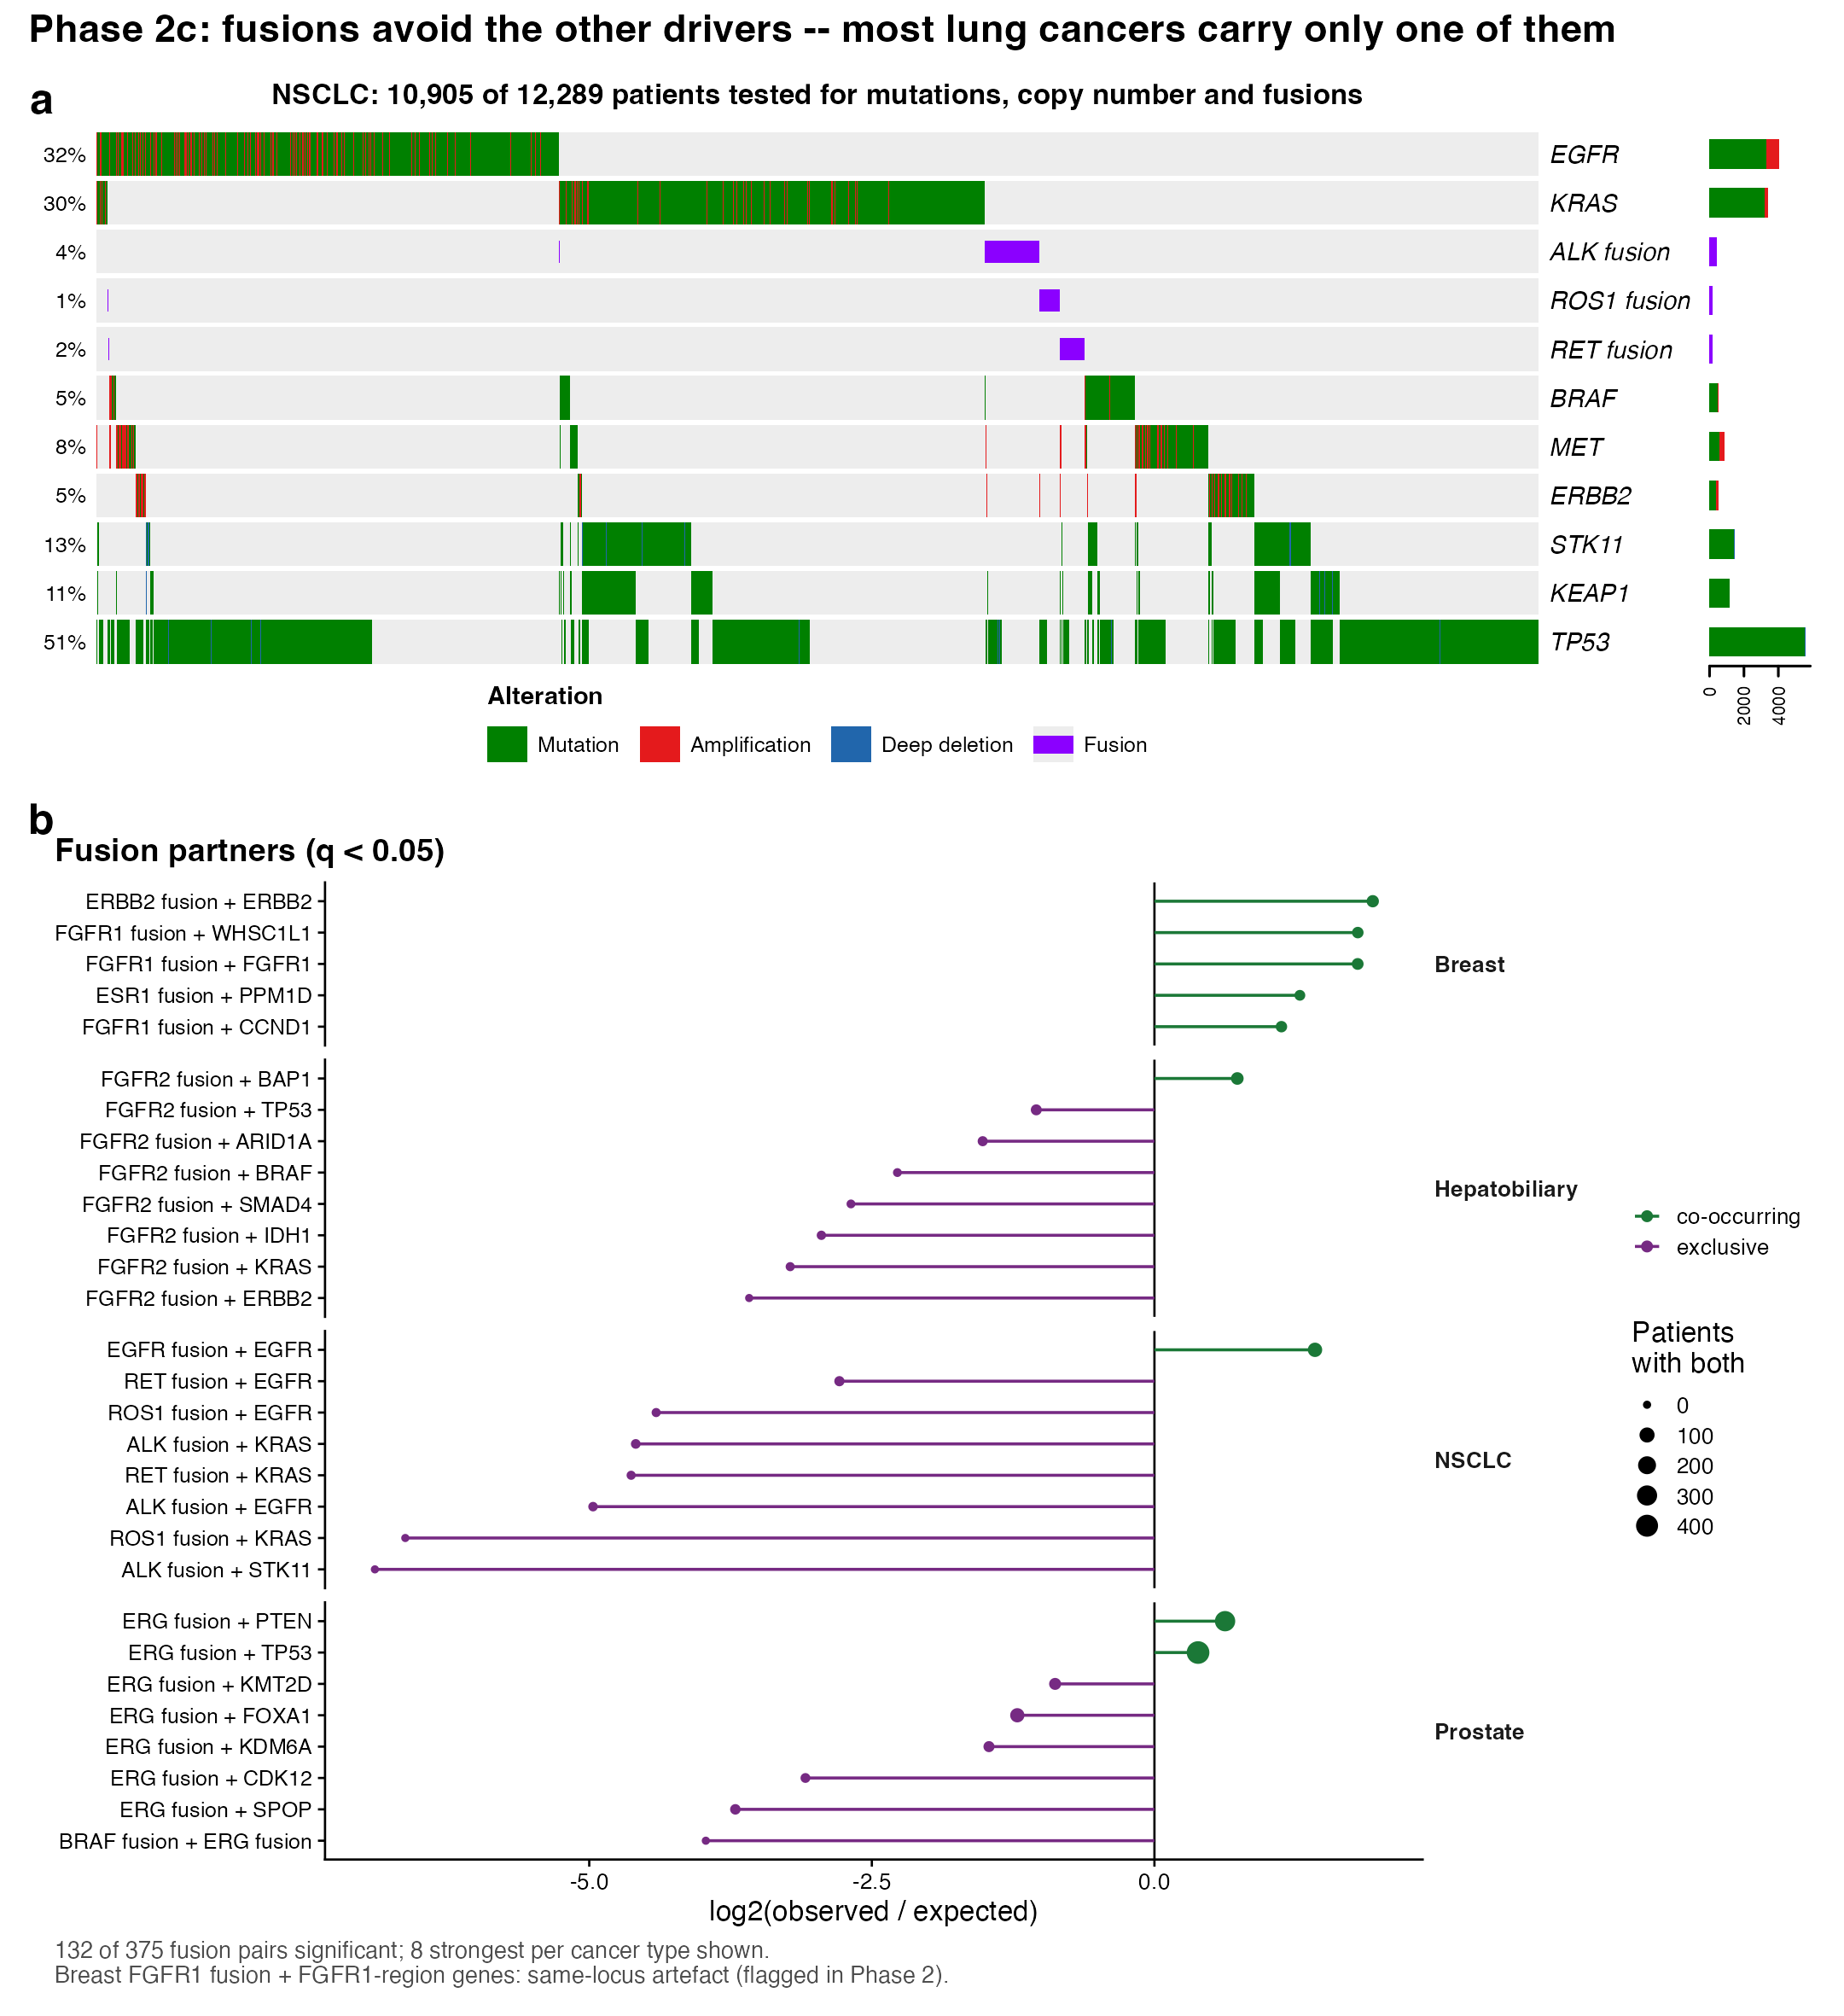

In [7]:
import subprocess, sys
from IPython.display import Image, display

# Rebuild this phase's figure from the saved outputs: export small CSVs, then run the R script
subprocess.run([sys.executable, "scripts/figures/00_export_figure_data.py"], cwd="..", check=True, capture_output=True)
subprocess.run(["Rscript", "scripts/figures/phase2c_extensions.R"], cwd="..", check=True, capture_output=True)
display(Image(filename="../results/figures/phase2c_extensions/figure_phase2c.png", width=1000))

## E. Mutation-load confounding (van de Haar 2019 diagnostic)

van de Haar et al. showed that genes mutated mostly in low-load tumours (negative *mutation load
association*, MLA) collect spurious mutual exclusivity: for every method they tested, a gene's MLA
correlated strongly and negatively with its number of significant exclusive pairs (r = -0.60 to
-0.87). MLA = load coefficient / standard error in a logistic regression of "gene altered" on TMB,
as in their STAR Methods. Same patients and pairs as the benchmark (Section F); then
re-run with hypermutated tumours (TMB 10-100) included (`21_mutation_load_confounding.py`; SELECT not
re-run there). Negative r = confounded.

In [8]:
from scipy.stats import pearsonr
ml = pd.read_parquet(P + "mutation_load_confounding.parquet")
mh = pd.read_parquet(P + "mutation_load_confounding_with_hyper.parquet")
methods = ["Fisher", "DISCOVER-style", "SELECT", "Conditional", "Conditional + subtype"]
pd.DataFrame({"non-hypermutated only (our design)": {m: pearsonr(ml.MLA, ml["ex_" + m])[0] for m in methods},
              "hypermutated included": {m: (pearsonr(mh.MLA, mh["ex_" + m])[0] if "ex_" + m in mh else np.nan)
                                        for m in methods}}).T.round(2)

,Fisher,DISCOVER-style,SELECT,Conditional,Conditional + subtype
non-hypermutated only (our design),0.08,0.18,0.07,0.09,0.12
hypermutated included,-0.24,-0.17,NaN,-0.23,-0.24


**Reading.** The strong confounding van de Haar report does not appear for any method on GENIE panels.
A weak version appears once hypermutated tumours are kept in, and it affects the conditional test as
much as Fisher -- so the test alone does not remove it. Analysing non-hypermutated tumours separately
removes it for every method: direct evidence for that design decision. The split and the conditional
test fix different problems (load confounding vs calibration).

## F. Method comparison on real data

The same patients, genes and pairs (9 large cancer types, `15_method_benchmark.py`), each method's
significant pairs (q < 0.05) re-tested in TCGA; then each method's K strongest pairs. Notebook 02b
compares the methods where the truth is known (simulation, textbook pairs); this is the real-data view,
where TCGA's smaller size limits how many true pairs can reach significance (notebook 02b, Section 4).

In [9]:
from scipy.stats import false_discovery_control
mb = pd.read_parquet(P + "method_benchmark.parquet")
M = {"A Fisher": ("p_fisher", "dir_fisher"), "B1 DISCOVER-style": ("p_discover", "dir_discover"),
     "B2 conditional": ("p_conditional", "dir_conditional"), "B3 conditional + subtype": ("p_cond_subtype", "dir_cond_subtype"),
     "D SELECT": ("p_select", "dir_select")}


def qv(df, pc):   # SELECT reports its own empirical FDR; the others use Benjamini-Hochberg
    return df["q_select"].to_numpy() if pc == "p_select" else false_discovery_control(df[pc].clip(1e-300, 1))


rows = []
for name, (pc, dc) in M.items():
    q = qv(mb, pc)
    s = mb[(q < .05) & mb.tcga_p.notna()]
    rows.append(dict(method=name, significant=int((q < .05).sum()), testable_in_TCGA=len(s),
                     same_direction_in_TCGA=(s.tcga_direction == s[dc]).mean(),
                     significant_in_TCGA=((s.tcga_p < .05) & (s.tcga_direction == s[dc])).mean(),
                     significant_opposite=int(((s.tcga_p < .05) & (s.tcga_direction != s[dc])).sum())))
pd.DataFrame(rows).round(3)

,method,significant,testable_in_TCGA,same_direction_in_TCGA,significant_in_TCGA,significant_opposite
0,A Fisher,995,632,0.837,0.286,0
1,B1 DISCOVER-style,1105,611,0.881,0.304,0
2,B2 conditional,857,524,0.880,0.338,0
3,B3 conditional + subtype,677,422,0.893,0.370,0
4,D SELECT,768,488,0.891,0.336,0


In [10]:
# Ranking: of each method's K strongest pairs (SELECT by its effect size), how many replicate in TCGA?
M4 = {"A Fisher": ("p_fisher", "dir_fisher"), "B1 DISCOVER-style": ("p_discover", "dir_discover"),
     "B2 conditional": ("p_conditional", "dir_conditional"), "B3 conditional + subtype": ("p_cond_subtype", "dir_cond_subtype")}
t = mb[mb.tcga_p.notna()]
scores = {name: (t[pc], t[dc]) for name, (pc, dc) in M4.items()}
scores["D SELECT (effect size)"] = (-t["es_select"], t["dir_select"])
pd.DataFrame({name: [((top.tcga_p < .05) & (top.tcga_direction == top._d)).mean()
                     for K in (50, 100, 200)
                     for top in [t.assign(_s=s.to_numpy(), _d=d.to_numpy()).nsmallest(K, "_s")]]
              for name, (s, d) in scores.items()}, index=["top 50", "top 100", "top 200"]).round(3)

,A Fisher,B1 DISCOVER-style,B2 conditional,B3 conditional + subtype,D SELECT (effect size)
top 50,0.84,0.920,0.92,0.860,0.960
top 100,0.77,0.790,0.83,0.780,0.840
top 200,0.57,0.635,0.63,0.555,0.605


**Reading.** SELECT ranks the very strongest pairs best (96% of its top 50 replicate vs 86% for ours) --
its effect size is a good ranking score. Beyond the top 100 the calibrated methods are similar. This is
about ordering the strongest pairs, not about which pairs are significant; for the significant lists,
ours replicates best (table above).